# 3. Methane: Visual Input and Output

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/03-VisualInput/031-VisualInput.ipynb)
:::

A **hand crafted** molecule is a powerful thing. We can set it up exactly as we like. But there is another way. We can use helper programs that enable the **visual creation** of a molecule and save its coordinates in a file that *Psi4* can read. These files will often need some further thought to get what you want out of *Psi4* but, after we start using molecules larger than benzene, we will appreciate the **graphical interface** (and curse it often).

When interpreting the **output**, we can evaluate energies and bond lengths and angles easily. But **visualization** of the whole molecule will help see the **relationships** between distant atoms and also quickly identify structures that optimized to a nonsense answer. In addition, we can now interpret more mathematical aspects of the output like mathematical **surfaces** that represent electron density and **molecular orbital** functions.

The two tools that we will use are *Avogadro* and *py3Dmol*. *Avogadro* is a desktop application for **building** molecules and **viewing** the files that *Psi4* writes. *py3Dmol* draws molecules and orbital surfaces right **inside** the notebook. Both have different **strengths** and we will get to know them both.

## Learning Goals

In this exercise, we will **accomplish** the following…

1.	Use *Avogadro* to **build** a molecule and save its coordinates in a file that *Psi4* can read.
2.	Use *Psi4* to write **files** of the results (*Molden*, *FCHK* and *cube* files) and open them in *Avogadro* and *py3Dmol*.
3.	Generate graphical **images** of the molecule and of surfaces that represent electron density and **molecular orbitals**.
4.	Identify the molecular orbitals that are most closely associated with the **bonding local molecular orbitals** and lone pair local MOs. How do you think about bonds and electronic structure? Do you think using **local** MOs that align with the Lewis structure or do you think using the molecular orbitals that describe the combined interactions of all atomic orbitals?

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

# The methane structure file used in this chapter
if IN_COLAB and not Path("methane.xyz").exists():
    !wget -q https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/book/03-VisualInput/methane.xyz

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Setting Up the Notebook

As in the previous chapter, the hidden **first code cell** imports *Psi4*, *py3Dmol*, *NumPy*, *pandas* and *Matplotlib* and applies the plot **style sheet**. You will see it when you open the notebook in *Jupyter*, *Visual Studio Code* or *Google Colab*. On *Colab* it also downloads the file `methane.xyz` that we use below.

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* with *conda* (*Psi4* cannot be installed with *pip*), install *py3Dmol* with *pip*, and download the plot style sheets and the `methane.xyz` file from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

Next, we tell *Psi4* how much of the computer it may use.

In [2]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"scf_type": "pk",
                  "cubic_grid_spacing": [0.4, 0.4, 0.4],
                  "cubic_grid_overage": [3.0, 3.0, 3.0]})


  Memory set to   3.725 GiB by Python driver.
  Threads set to 4 by Python driver.


| Line | Notes |
| :---- | :---- |
| `"scf_type": "pk"` | Calculate the electron repulsion integrals **exactly**, as in the previous chapter. |
| `"cubic_grid_spacing": [0.4, 0.4, 0.4]` | Later we will ask *Psi4* to write orbitals and densities as **cube files**: values on a 3D grid of points. This sets the distance between grid points (in Bohr) along *x*, *y* and *z*. The default is 0.2 Bohr. Our coarser grid makes files that are less than an **eighth** of the size, and they still look fine for methane. |
| `"cubic_grid_overage": [3.0, 3.0, 3.0]` | How far (in Bohr) the grid extends **beyond** the outermost atoms. The default is 4.0. |

```{note}
Every *py3Dmol* picture of an orbital carries a copy of its cube file **inside** the notebook. With finer grids, this notebook quickly grows to tens of megabytes. If your pictures look jagged, make the spacing smaller and accept a bigger notebook.
```

### Some Helpful Tools

We will reuse the five functions from the previous chapter and add **two new ones** for drawing surfaces. In the webbook, click on the code section to expand it. Run the cell below once.

In [3]:
def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def plot_history(history, title):
    energies = np.array(history["energy"])
    delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
    steps = np.arange(1, len(energies) + 1)

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
    ax.plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    ax.set_xticks(steps)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel(r"$E - E_{final}$ (kJ/mol)")
    ax.set_title(title)
    plt.show()

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

def show_orbital(mol, cube_file, isoval=0.05):
    with open(cube_file) as f:
        cube = f.read()
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.addVolumetricData(cube, "cube", {"isoval": isoval, "color": "#FFB3BA", "opacity": 0.85})
    view.addVolumetricData(cube, "cube", {"isoval": -isoval, "color": "#AEC6CF", "opacity": 0.85})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def show_density_esp(mol, density_file, esp_file, isoval=0.002, esp_range=0.02):
    with open(density_file) as f:
        density = f.read()
    with open(esp_file) as f:
        esp = f.read()
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.addVolumetricData(density, "cube", {"isoval": isoval, "opacity": 0.9,
                                             "voldata": esp, "volformat": "cube",
                                             "volscheme": {"gradient": "rwb",
                                                           "min": -esp_range, "max": esp_range}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

| Function | What it does |
| :---- | :---- |
| `show_molecule(mol)` | Draws the molecule with *py3Dmol*, as in the previous chapter. |
| `bond_length(mol, i, j)` | The distance between atoms `i` and `j` in **&Aring;ngstroms**. |
| `bond_angle(mol, i, j, k)` | The angle `i`&ndash;`j`&ndash;`k` in **degrees**, with `j` in the middle. |
| `plot_history(history, title)` | **Plots** the energy at each step of an optimization relative to the final energy. |
| `search_file(filename, text)` | **Prints** every line of a file that contains `text`. |
| `show_orbital(mol, cube_file, isoval)` | **New.** Reads a cube file and draws the molecule with two **isosurfaces**: one where the orbital has the value `+isoval` (pink) and one where it has the value `-isoval` (blue). The two colours are the two **phases** of the orbital. The default `isoval` of 0.05 is a good place to start. |
| `show_density_esp(mol, density_file, esp_file, isoval, esp_range)` | **New.** Draws the surface where the **electron density** has the value `isoval` (0.002 electrons per cubic Bohr is a common choice for the "outside" of a molecule) and **colours** it by the value of the electrostatic potential from a second cube file: red for negative, white for zero and blue for positive, from `-esp_range` to `+esp_range` Hartree per unit charge. |

The *py3Dmol* function `addVolumetricData()` does the hard work in both new functions. It turns a grid of numbers into a **surface**.

## Making Methane

Open *Avogadro*. Select the **Draw** tool (the pencil), choose **carbon** as the element, and click once in the empty window. *Avogadro* adds the **hydrogens** for you, as long as the `Adjust Hydrogens` option for the Draw tool is checked (if not, use `Build` &rarr; `Add Hydrogens`). Then select `Extensions` &rarr; `Optimize Geometry` to clean up the structure with a quick **molecular mechanics** optimization. (Menu names move around a little between versions of *Avogadro*. Explore.)

Now save the molecule with `File` &rarr; `Save As...` and choose the **XYZ** format. Call it `methane.xyz` and save it in the same folder as this notebook.

```{note}
*Avogadro* can also write a complete *Psi4* input file for you (look in the `Input` menu). Those files are written for running *Psi4* from the command line. We drive *Psi4* from *Python*, so all we need from *Avogadro* is the **coordinates**.
```

An *xyz* file is about as simple as a file can be. Let us look at it. The file `methane.xyz` that comes with this notebook is a methane molecule saved in this format. Replace it with your own.

In [4]:
with open("methane.xyz") as f:
    xyz_lines = f.readlines()

print("".join(xyz_lines))

5
methane
C      1.20331    -0.41274     0.05470
H      2.04833    -0.24438    -0.61675
H      0.87809     0.54137     0.47743
H      0.37864    -0.86481    -0.50215
H      1.50850    -1.08348     0.86259



| Line | Notes |
| :---- | :---- |
| `with open("methane.xyz") as f:` | Opens the file for reading. The file is **closed** again when the indented block ends. |
| `xyz_lines = f.readlines()` | Reads the whole file into a *Python* **list**, one item per line. |

The **first line** is the number of atoms. The **second line** is a comment (here, just a name). Every other line is an atom: the element and its *x*, *y* and *z* coordinates in &Aring;ngstroms. Those last five lines are exactly what `psi4.geometry()` wants, so we can hand them over directly.

## Methane Without Symmetry

*Avogadro* placed our methane wherever it liked in space, and molecular mechanics is not perfect, so the structure is **close** to tetrahedral but not exactly. In *GAMESS*, efforts to declare symmetry for files created by builder programs often fail, because *GAMESS* requires perfection when you are declaring symmetry. *Psi4* will try to **detect** the symmetry itself, but it also needs the structure to be symmetrical to within a small tolerance. For our first calculation, we will **not use** symmetry at all. We will see what that does to the orbitals later.

In [5]:
methane = psi4.geometry("0 1\n" + "".join(xyz_lines[2:]) + "symmetry c1\n")

methane.update_geometry()
print("Full point group:         ", methane.get_full_point_group())
print("Computational point group:", methane.schoenflies_symbol())
show_molecule(methane)

Full point group:          C1
Computational point group: c1


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `"0 1\n"` | The **charge** and **multiplicity** line. `\n` is the *Python* code for a **new line**. |
| `"".join(xyz_lines[2:])` | All the lines of the file from the **third** line onward (*Python* counts from zero, so line `2` is the third line), glued back together into one block of text. |
| `"symmetry c1\n"` | Tells *Psi4* **not** to use symmetry. *C<sub>1</sub>* is the point group with no symmetry elements other than the identity. |
| `+` | Adding strings of text together **joins** them, so the three parts become one molecule description. |

*Psi4* reports *C<sub>1</sub>*. In fact, *Psi4* finds only *C<sub>1</sub>* for this file even without the `symmetry c1` line. Try deleting it and see. The coordinates are too far from a perfect tetrahedron for *Psi4* to recognize it. If your own file from *Avogadro* is closer to perfect, *Psi4* might detect *T<sub>d</sub>* symmetry, and the `symmetry c1` line makes sure that we all get the same kind of calculation.

### Optimizing Methane

We will use a better **level of theory** than in the previous chapter: Hartree-Fock with the **6-311++G(d,p)** basis set. This is a *triple split valence* basis set (6-311). It adds **polarization** functions (*d* orbitals on carbon and *p* orbitals on hydrogen, the "(d,p)") and **diffuse** functions on all atoms (the "++"). Methane is tiny, so this is still a matter of seconds.

Optimizer: Optimization complete!
Final energy: -40.20914979 Hartree
Steps taken: 3
C-H lengths: [np.float64(1.0843), np.float64(1.0844), np.float64(1.0843), np.float64(1.0844)]
H-C-H angles: [np.float64(109.47), np.float64(109.49), np.float64(109.46), np.float64(109.48), np.float64(109.45), np.float64(109.47)]


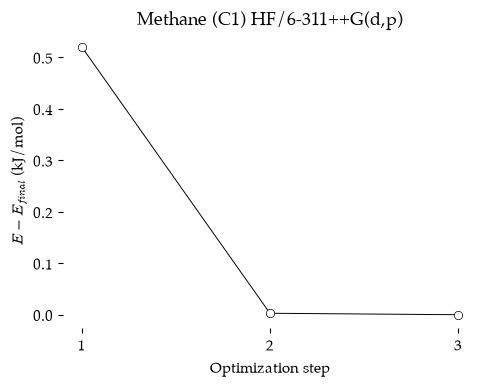

In [6]:
psi4.set_output_file("methane_c1_opt.out", False)

E_opt, hist_c1 = psi4.optimize("hf/6-311++g(d,p)", molecule=methane, return_history=True)

print(f"Final energy: {E_opt:.8f} Hartree")
print("Steps taken:", len(hist_c1["energy"]))
print("C-H lengths:", [round(bond_length(methane, 0, h), 4) for h in [1, 2, 3, 4]])
print("H-C-H angles:", [round(bond_angle(methane, i, 0, j), 2)
                        for i, j in [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]])
plot_history(hist_c1, "Methane (C1) HF/6-311++G(d,p)")

| Line | Notes |
| :---- | :---- |
| `"hf/6-311++g(d,p)"` | The level of theory. This is the same basis set as `GBASIS=N311 NGAUSS=6 NDFUNC=1 NPFUNC=1 DIFFSP=.TRUE. DIFFS=.TRUE.` in a *GAMESS* input file. |
| `for h in [1, 2, 3, 4]` | A *Python* **list comprehension**. It measures the C&ndash;H distance from atom `0` (carbon) to each hydrogen in turn and collects the results in a list. |
| `for i, j in [(1, 2), ...]` | The same idea for all **six** H&ndash;C&ndash;H angles. |
| `round(..., 4)` | Rounds each number to four decimal places so the list is easy to read. |

The optimization took only **three** steps. Molecular mechanics in *Avogadro* gave us a very good starting structure, only 0.52 *kJ/mol* above the final energy of &minus;40.20914979 Hartree. The four C&ndash;H bonds are 1.0843 or 1.0844 &Aring; and the six H&ndash;C&ndash;H angles range from 109.45&deg; to 109.49&deg;. Compare these with the experimental structure of methane (C&ndash;H 1.087 &Aring; and the perfect tetrahedral angle of 109.47&deg;). Without symmetry, nothing forces the four bonds to be **exactly** the same. They are the same only to within the **convergence criteria** of the optimizer. Let us look at those.

In [7]:
search_file("methane_c1_opt.out", "~")

   410: 	----------------------------------------------------------------------------------------------~
   411: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
   412: 	----------------------------------------------------------------------------------------------~
   413: 	  Convergence Criteria     1.00e-06 *    3.00e-04 *             o    1.20e-03 *             o~
   414: 	----------------------------------------------------------------------------------------------~
   415: 	     1     -40.20895158   -4.02e+01      6.35e-03      2.57e-03 o    1.84e-02      7.45e-03 o  ~
   815: 	     2     -40.20914873   -1.97e-04      4.54e-04      1.89e-04 o    1.22e-03      5.36e-04 o  ~
  1214: 	     3     -40.20914979   -1.07e-06      1.65e-05 *    7.81e-06 o    2.12e-04 *    1.10e-04 o  ~


The criteria are the same as in the previous chapter: a change in energy below 1.0 &times; 10<sup>&minus;6</sup> Hartree, a largest force below 3.0 &times; 10<sup>&minus;4</sup> and a largest displacement below 1.2 &times; 10<sup>&minus;3</sup>. Look at step 3. The force and the displacement are marked `*`, but the change in energy (1.07 &times; 10<sup>&minus;6</sup> Hartree) **just missed** its target. *Psi4* stopped anyway. With these default criteria (called `QCHEM` in the *Psi4* manual), an optimization is converged when the largest force **and** either the energy change **or** the largest displacement have met their targets. The *GAMESS* version of this calculation used `OPTTOL=0.0001`, which requires the largest component of the gradient to be below 1.0 &times; 10<sup>&minus;4</sup> Hartree/Bohr and the RMS gradient to be below a third of that. The two programs do not measure convergence in quite the same way, so do not expect their structures to agree in the last decimal place. Our final largest force (1.65 &times; 10<sup>&minus;5</sup>) would satisfy either.

### The Wavefunction

An optimization gives us the structure. To look at the **orbitals** we need the **wavefunction** for the optimized structure. We run a single-point energy calculation and ask *Psi4* to give us the wavefunction too. Then we save it in two file formats that *Avogadro* can read.

In [8]:
psi4.set_output_file("methane_c1.out", False)

E_c1, wfn_c1 = psi4.energy("hf/6-311++g(d,p)", molecule=methane, return_wfn=True)
print(f"Energy: {E_c1:.8f} Hartree")

psi4.molden(wfn_c1, "methane_c1.molden")
psi4.fchk(wfn_c1, "methane_c1.fchk")

Energy: -40.20914979 Hartree


| Line | Notes |
| :---- | :---- |
| `psi4.energy(..., return_wfn=True)` | A **single point** energy for the structure as it stands. `methane` already holds the optimized coordinates. `return_wfn=True` returns the **wavefunction** object as well as the energy. |
| `E_c1, wfn_c1 =` | The energy goes into `E_c1` and the wavefunction into `wfn_c1`. The wavefunction holds the **basis set**, the **molecular orbital** coefficients, the orbital **energies** and much more. |
| `psi4.molden(wfn_c1, "methane_c1.molden")` | Writes a **Molden** file: the structure, the basis set and the molecular orbitals. Many viewing programs can read it, including *Avogadro*. |
| `psi4.fchk(wfn_c1, "methane_c1.fchk")` | Writes a **formatted checkpoint** file, the format used by the *Gaussian* program. It holds the same information plus the electron density. *Avogadro* can read this too. |

The energy is the same as the last step of the optimization, &minus;40.20914979 Hartree, as it should be.

## Viewing in *Avogadro*

Use *Avogadro* to **open** `methane_c1.molden` (or `methane_c1.fchk`). You will see an **image** of the methane molecule. Practice **rotating** it and **zooming** in and out.

We can **measure** lengths and angles in *Avogadro*. Select the **Measure** tool (the ruler) and click on two atoms to see the distance between them. Click on a third atom to see the angle, and a fourth to see the dihedral angle. You can **measure** lengths, angles and torsions right off the screen. You can **display** atom numbers by turning on the `Labels` display type. **Explore** the menus and see what you can do.

You can **save** the image in the window using `File` &rarr; `Export` &rarr; `Graphics`. Explore the **options** and see what makes the best image file for you.

We can **display** surfaces with `Analysis` &rarr; `Create Surfaces...`. Choose the **electron density** surface, coloured by **electrostatic potential**, and choose settings until you get a **picture** that you like. Or, we can make that picture right here.

## Electron Density and Electrostatic Potential

*Psi4* can write the electron density and the electrostatic potential on a grid of points as **cube files** with the `psi4.cubeprop()` function. We draw them with our `show_density_esp()` function.

In [9]:
psi4.set_output_file("methane_esp.out", False)
psi4.set_options({"scf_type": "df"})

E_df, wfn_df = psi4.energy("hf/6-311++g(d,p)", molecule=methane, return_wfn=True)
print(f"Energy (density fitted): {E_df:.8f} Hartree")

Path("cube_esp").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["density", "esp"],
                  "cubeprop_filepath": "cube_esp"})
psi4.cubeprop(wfn_df)
psi4.set_options({"scf_type": "pk"})

show_density_esp(methane, "cube_esp/Dt.cube", "cube_esp/ESP.cube")

Energy (density fitted): -40.20914918 Hartree


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `psi4.set_options({"scf_type": "df"})` | *Psi4* calculates the electrostatic potential using **density fitting**, so it needs a wavefunction that was calculated with density fitting. We switch from `pk` to `df` for this one job. |
| `"cubeprop_tasks": ["density", "esp"]` | What `psi4.cubeprop()` should calculate: the electron **density** and the electrostatic potential (**ESP**). |
| `"cubeprop_filepath": "cube_esp"` | The **folder** where the cube files are written. |
| `Path("cube_esp").mkdir(exist_ok=True)` | **Makes** that folder. *Psi4* will complain if it does not exist. `exist_ok=True` means it is fine if the folder is already there. |
| `psi4.cubeprop(wfn_df)` | Calculates the values on the grid and writes the cube files. The total density is `Dt.cube` and the potential is `ESP.cube`. (It also writes `Da.cube`, `Db.cube` and `Ds.cube` for the alpha, beta and spin densities.) |
| `psi4.set_options({"scf_type": "pk"})` | Switches back to exact integrals for the rest of the chapter. |

The density-fitted energy (&minus;40.20914918 Hartree) differs from the exact one by only 6 &times; 10<sup>&minus;7</sup> Hartree (0.002 *kJ/mol*). Density fitting is a very good shortcut.

The surface is the electron density "skin" of methane, coloured according to molecular electrostatic potential (**MEP**). Methane is very **nonpolar** so the MEP is mostly one colour. On this surface it ranges from only about &minus;0.003 to +0.023 Hartree per unit charge (&minus;7 to +61 *kJ/mol*). The faintly **blue** patches over the hydrogens are slightly positive. Molecules with heteroatoms will be more revealing in this regard. Rotate the molecule and look.

## Molecular Orbitals

We often see **molecular orbital diagrams** in textbooks. Let us try to make our own for methane. First, what are the orbital **energies**?

In [10]:
eps = wfn_c1.epsilon_a().np
n_occ = wfn_c1.nalpha()

orbitals = pd.DataFrame({
    "MO": np.arange(1, 9),
    "Energy (Eh)": eps[:8],
    "Energy (kJ/mol)": eps[:8] * psi4.constants.hartree2kJmol,
    "Occupied": ["yes"] * n_occ + ["no"] * (8 - n_occ),
})
orbitals.round(4)

,MO,Energy (Eh),Energy (kJ/mol),Occupied
0,1,-11.2053,-29419.4753,yes
1,2,-0.9451,-2481.2872,yes
2,3,-0.5461,-1433.8989,yes
3,4,-0.5461,-1433.7896,yes
4,5,-0.5461,-1433.6581,yes
5,6,0.0419,109.9517,no
6,7,0.0784,205.7635,no
7,8,0.0784,205.7740,no


| Line | Notes |
| :---- | :---- |
| `wfn_c1.epsilon_a().np` | The **orbital energies** (the Greek letter *&epsilon;*) of the **alpha** electrons, as a *NumPy* array, lowest first. In RHF, the beta electrons have the same orbitals. |
| `wfn_c1.nalpha()` | The number of alpha electrons: **5**, so five doubly occupied orbitals for the 10 electrons of methane. |
| `eps[:8]` | The **first eight** orbital energies: the five occupied orbitals and the three lowest empty ones. |
| `["yes"] * n_occ + ["no"] * (8 - n_occ)` | Multiplying a list repeats it, adding lists joins them: five `"yes"` followed by three `"no"`. |

There are **five** occupied orbitals.

- MO 1 (&minus;11.2053 Hartree) is the carbon **1*s*** core orbital, far below everything else.
- MO 2 (&minus;0.9451 Hartree) is the bonding combination of the carbon **2*s*** orbital with all four hydrogen 1*s* orbitals in phase.
- MOs 3, 4 and 5 (&minus;0.5461 Hartree) are the **three** combinations of the carbon **2*p*** orbitals with the hydrogen 1*s* orbitals. They are the **HOMOs**. In *T<sub>d</sub>* symmetry they are **degenerate** (they have the same energy).

But look closely at the energies in *kJ/mol*. The three HOMOs are not quite equal: &minus;1433.90, &minus;1433.79 and &minus;1433.66 *kJ/mol*. Our structure is tetrahedral only to within the convergence criteria, and without symmetry nothing forces the three orbitals to be **exactly** degenerate. A difference of 0.2 *kJ/mol* in 1434 is nothing to worry about.

The LUMO (MO 6, +0.0419 Hartree) is **above zero**. Since we included diffuse functions, the lowest empty orbitals are big and fluffy, and they do not mean very much chemically.

### Visualizing MOs

Now let us **see** the orbitals. We ask `psi4.cubeprop()` for cube files of the three HOMOs, numbered 3, 4 and 5.

In [11]:
Path("cube_c1").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubeprop_orbitals": [3, 4, 5, 6],
                  "cubeprop_filepath": "cube_c1"})
psi4.cubeprop(wfn_c1)

for cube_file in sorted(Path("cube_c1").glob("Psi_a_*.cube")):
    print(cube_file.name)

Psi_a_3_3-A.cube
Psi_a_4_4-A.cube
Psi_a_5_5-A.cube
Psi_a_6_6-A.cube


| Line | Notes |
| :---- | :---- |
| `"cubeprop_tasks": ["orbitals"]` | Write cube files of **molecular orbitals**. |
| `"cubeprop_orbitals": [3, 4, 5, 6]` | Which orbitals, counting from **one** in order of energy. Leave this out and *Psi4* will write cube files for **all** 50 orbitals. |
| `Path("cube_c1").glob("Psi_a_*.cube")` | Finds every file in the folder whose name **matches** the pattern. `*` matches anything. `sorted()` puts them in order. |

The file names tell us what is inside. In `Psi_a_3_3-A.cube`, `a` means an **alpha** orbital, the first `3` is the orbital **number** and `3-A` means it is the third orbital of **symmetry** type *A*. In *C<sub>1</sub>* every orbital is type *A*. We also asked for the LUMO (orbital 6). You can look at it with `show_orbital()` yourself. Try `isoval=0.02`. Now the HOMOs.

In [12]:
show_orbital(methane, "cube_c1/Psi_a_3_3-A.cube")
show_orbital(methane, "cube_c1/Psi_a_4_4-A.cube")
show_orbital(methane, "cube_c1/Psi_a_5_5-A.cube")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

These are the three HOMOs of methane. Rotate them with your mouse. Each has **two lobes** of opposite phase, like a carbon 2*p* orbital, merged with the hydrogen 1*s* orbitals near each lobe. We see the familiar methane HOMO there but it is not **perfectly** symmetrical. The three images look like the same orbital pointing in **different directions**, but none of them lines up neatly with the C&ndash;H bonds, or with each other. We did not use symmetry in our calculations, so nothing told *Psi4* how to **orient** the three degenerate orbitals.

## *T<sub>d</sub>* Methane

We can **construct** a symmetrical structure of methane **manually**. A tetrahedron fits neatly inside a cube. We place the carbon at the center of a cube and the four hydrogens on **alternating corners**, as in the hint for the exercise in the previous chapter. In the *GAMESS* version of this exercise, I first optimized this structure at the AM1 semi-empirical level and then copied the coordinates into an HF/6-311G(d,p)++ job. *Psi4* does not have semi-empirical methods. That is fine: methane is small enough to optimize directly at HF/6-311++G(d,p).

In [13]:
methane_td = psi4.geometry("""
0 1
C    0.0   0.0   0.0
H    0.7   0.7   0.7
H   -0.7  -0.7   0.7
H   -0.7   0.7  -0.7
H    0.7  -0.7  -0.7
symmetry d2
no_reorient
""")

methane_td.update_geometry()
print("Full point group:         ", methane_td.get_full_point_group())
print("Computational point group:", methane_td.schoenflies_symbol())

Full point group:          Td
Computational point group: d2


| Line | Notes |
| :---- | :---- |
| `H 0.7 0.7 0.7` ... | Each hydrogen sits on a **corner** of a cube centred on the carbon. Two of the four coordinates in each line are negative, so the hydrogens are on alternating corners. This guess has C&ndash;H bonds of $\sqrt{3} \times 0.7 = 1.21$ &Aring;, a bit long. |
| `symmetry d2` | Use the point group *D<sub>2</sub>* for the calculation. |
| `no_reorient` | Do **not** rotate the molecule. Keep it exactly where we put it, with the *x*, *y* and *z* axes passing through the **faces** of the cube. |

*Psi4* recognizes that the **full** point group is *T<sub>d</sub>*. But *T<sub>d</sub>* is not one of the point groups that *Psi4* can calculate with. Remember that *Psi4* only uses *D<sub>2h</sub>* and its subgroups. The largest of these that fits methane in **this orientation** is *D<sub>2</sub>*: three perpendicular *C<sub>2</sub>* axes along *x*, *y* and *z*. Each one passes through the carbon and the middle of two opposite faces of the cube. *GAMESS*, by contrast, can use the full *T<sub>d</sub>* group.

In [14]:
psi4.set_output_file("methane_td_opt.out", False)

E_td_opt, hist_td = psi4.optimize("hf/6-311++g(d,p)", molecule=methane_td, return_history=True)

print(f"Final energy: {E_td_opt:.8f} Hartree")
print("Steps taken:", len(hist_td["energy"]))
print(f"C-H length:  {bond_length(methane_td, 0, 1):.4f} Angstrom")
print(f"H-C-H angle: {bond_angle(methane_td, 1, 0, 2):.4f} degrees")

start = next(i for i, line in enumerate(open("methane_td_opt.out")) if "Final optimized geometry" in line)
print("".join(open("methane_td_opt.out").readlines()[start:start + 12]))

Optimizer: Optimization complete!
Final energy: -40.20914967 Hartree
Steps taken: 6
C-H length:  1.0846 Angstrom
H-C-H angle: 109.4712 degrees
    Final optimized geometry and variables:
    Molecular point group: d2
    Full point group: Td

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

    C            0.000000000000     0.000000000000     0.000000000000
    H            0.626181259404     0.626181259404     0.626181259404
    H           -0.626181259404    -0.626181259404     0.626181259404
    H           -0.626181259404     0.626181259404    -0.626181259404
    H            0.626181259404    -0.626181259404    -0.626181259404




The optimization took **six** steps from our long-bonded guess. The structure stayed **exactly** tetrahedral at every step: the H&ndash;C&ndash;H angle is 109.4712&deg; and all four C&ndash;H bonds are 1.0846 &Aring;. Each hydrogen is now at &plusmn;0.626181 &Aring; along each axis.

In the *GAMESS* version of this job, the *T<sub>d</sub>* coordinates came from the AM1 optimization (0.6260053 &Aring;, a C&ndash;H bond of 1.0843 &Aring;), and the HF/6-311G(d,p)++ job was only a single point energy at that structure. Here the structure has been optimized at the HF level. The cheap AM1 bond length turned out to be only 0.0003 &Aring; shorter.

Do not expect the *Psi4* and *GAMESS* energies to agree exactly, even for the same structure. The basis sets are not quite the same. *GAMESS* uses six **Cartesian** *d* functions on carbon by default, while *Psi4* uses five **spherical** *d* functions for the 6-311G family. (Set the *Psi4* option `"puream": False` if you want Cartesian *d* functions.)

The final energy (&minus;40.20914967 Hartree) is slightly **higher** than our *C<sub>1</sub>* result (&minus;40.20914979 Hartree), by 1.2 &times; 10<sup>&minus;7</sup> Hartree, or 0.0003 *kJ/mol*. That is far below the energy convergence criterion of 1.0 &times; 10<sup>&minus;6</sup> Hartree. Both optimizations stopped **near** the bottom of the same energy well, and neither is exactly at the bottom. Tighter criteria would bring them closer together.

Now the wavefunction and the orbitals.

In [15]:
psi4.set_output_file("methane_td.out", False)

E_td, wfn_td = psi4.energy("hf/6-311++g(d,p)", molecule=methane_td, return_wfn=True)
print(f"Energy: {E_td:.8f} Hartree")
print("Orbital energies (Eh):", np.round(wfn_td.epsilon_a_subset("AO", "ALL").np[:6], 5))

psi4.molden(wfn_td, "methane_td.molden")

Path("cube_td").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubeprop_orbitals": [3, 4, 5],
                  "cubeprop_filepath": "cube_td"})
psi4.cubeprop(wfn_td)

for cube_file in sorted(Path("cube_td").glob("Psi_a_*.cube")):
    print(cube_file.name)
    show_orbital(methane_td, cube_file)

Energy: -40.20914967 Hartree
Orbital energies (Eh): [-11.20539000  -0.94498000  -0.54604000  -0.54604000  -0.54604000
   0.04188000]
Psi_a_3_1-B3.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_4_1-B2.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_5_1-B1.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `wfn_td.epsilon_a_subset("AO", "ALL")` | With symmetry, *Psi4* stores the orbitals in **blocks**, one for each symmetry type. This function gives all of them in a single list, sorted by energy. |

This time the three HOMOs have **exactly** the same energy, &minus;0.54604 Hartree. The file names show that they belong to the three different symmetry types *B<sub>1</sub>*, *B<sub>2</sub>* and *B<sub>3</sub>* of the *D<sub>2</sub>* point group. Symmetry forces each one to line up with one of the three *C<sub>2</sub>* axes (*x*, *y* or *z*).

### MOs for *T<sub>d</sub>* Methane

When I **displayed** the HOMOs for this symmetrical calculation the orbitals were perfect. Rotate the three images. Each is **exactly the same shape**, pointed along a different axis. Each lobe covers one **face** of the cube and encloses the two hydrogens on the corners of that face.

It should be noted that both sets of MOs were really the same. It is exactly the same math. The less symmetrical images were produced using axes that did not perfectly align with the **elements of symmetry** of the orbitals. However, just because there was a little more *x* and a little less *y* does not change the way the orbitals behave. It's just how the **picture** is calculated, the underlying math of the MO never changes.

We can find these orbitals in the **output file** too. *Psi4* lists the orbital energies with their symmetry labels.

In [16]:
search_file("methane_td.out", "Doubly Occupied")
with open("methane_td.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Doubly Occupied:" in line)
print("".join(lines[start:start + 12]))

   192:     Doubly Occupied:
    Doubly Occupied:                                                      

       1A    -11.205395     2A     -0.944982     1B3    -0.546043  
       1B2    -0.546043     1B1    -0.546043  

    Virtual:                                                              

       3A      0.041879     2B3     0.078377     2B2     0.078377  
       2B1     0.078377     3B2     0.152898     3B1     0.152898  
       3B3     0.152898     4A      0.189454     4B3     0.309574  
       4B1     0.309574     4B2     0.309574     5A      0.382778  
       5B1     0.551130     5B2     0.551130     5B3     0.551130  



The occupied orbitals are `1A` (the carbon 1*s* core), `2A` (the all-in-phase 2*s* combination) and `1B1`, `1B2`, `1B3`, the three HOMOs with **identical** energies of &minus;0.546043 Hartree. The LUMO, `3A` at +0.041879 Hartree, is followed by another set of three degenerate orbitals (`2B1`, `2B2`, `2B3`). In *T<sub>d</sub>* language, the 1*s* and 2*s* orbitals are *a*<sub>1</sub> orbitals and each set of three degenerate orbitals is a *t*<sub>2</sub> set. *Psi4* only uses the *D<sub>2</sub>* labels, so each *t*<sub>2</sub> set shows up as one *B<sub>1</sub>*, one *B<sub>2</sub>* and one *B<sub>3</sub>* orbital.

## Local Bonding Orbitals

We are used to describing **bonds** around second-row elements like carbon as *sp*, *sp<sup>2</sup>*, or *sp<sup>3</sup>*. An *sp<sup>3</sup>* bonding MO can be constructed from the overlap of the carbon *sp<sup>3</sup>* AO and the hydrogen's *s*-orbital. This would be a **simple model** that describes the electron pair for that bond (not really) and relates more directly to **Lewis structure** (if you prefer stick drawings to the truth of math.)

We can make these **local** orbitals from the true molecular orbitals. The occupied MOs can be **mixed** together in any way we like (as long as they remain orthogonal) without changing the total electron density or the energy. A **localization** method finds the mixture where each orbital is as **compact** as possible. In the *GAMESS* version of this exercise we used the Edmiston&ndash;Ruedenberg method (`LOCAL=RUEDNBRG`). *Psi4* does not have that one, but it has two others: **Boys** (also called Foster&ndash;Boys) localization, which makes each orbital as small as possible in space, and **Pipek&ndash;Mezey** localization, which places each orbital on as few atoms as possible. For a simple molecule like methane, all three give the familiar C&ndash;H **bonds**. We will use Boys.

In [17]:
C_occ = wfn_c1.Ca_subset("AO", "OCC")

boys = psi4.core.Localizer.build("BOYS", wfn_c1.basisset(), C_occ)
boys.localize()
L = boys.L.np

F = wfn_c1.Fa().np
eps_local = np.diag(L.T @ F @ L)

print("Converged:", boys.converged)
print("Canonical MO energies (Eh):", np.round(eps[:n_occ], 5))
print("Local MO energies (Eh):    ", np.round(eps_local, 5))
print(f"Sum, canonical: {eps[:n_occ].sum():.6f}   Sum, local: {eps_local.sum():.6f}")

Converged: True
Canonical MO energies (Eh): [-11.20529000  -0.94507000  -0.54614000  -0.54610000  -0.54605000]
Local MO energies (Eh):     [-11.17133000  -0.65432000  -0.65435000  -0.65434000  -0.65430000]
Sum, canonical: -13.788655   Sum, local: -13.788655


| Line | Notes |
| :---- | :---- |
| `wfn_c1.Ca_subset("AO", "OCC")` | The **coefficients** of the occupied orbitals: how much of each of the 50 basis functions is in each of the 5 occupied MOs. We use the *C<sub>1</sub>* wavefunction because a localized orbital does not belong to any symmetry type. |
| `psi4.core.Localizer.build("BOYS", ...)` | Sets up a **Boys** localization for these orbitals in this basis set. Use `"PIPEK_MEZEY"` for the other method. |
| `boys.localize()` | Does the work: mixes the orbitals until they are as **compact** as possible. |
| `L = boys.L.np` | The coefficients of the five **local** orbitals as a *NumPy* array. |
| `F = wfn_c1.Fa().np` | The **Fock matrix**. In Hartree-Fock theory, this matrix holds the energy of an electron in each basis function and the interactions between them. |
| `np.diag(L.T @ F @ L)` | The **energy** of each local orbital. `@` is matrix multiplication and `L.T` is the transpose of `L`. `np.diag()` takes the numbers on the diagonal. |

The localization **converged**. We get back one core orbital (&minus;11.1713 Hartree) and **four** orbitals with the same energy, &minus;0.6543 Hartree. Four equivalent orbitals for four equivalent C&ndash;H bonds! The local bond energy lies **between** the 2*a*<sub>1</sub> MO (&minus;0.9451) and the HOMOs (&minus;0.5461). It is almost the average of those four MOs. (Not exactly, because a little of the core orbital is mixed in too.) The **sum** of the orbital energies is the same for both sets (&minus;13.788655 Hartree). We have **rearranged** the same electrons, not changed them.

Now let us look at two of them. To draw them, we make a **copy** of the wavefunction, put the local orbitals in place of the canonical ones, and give that to `psi4.cubeprop()`.

In [18]:
wfn_local = wfn_c1.c1_deep_copy(wfn_c1.basisset())
wfn_local.Ca().np[:, :n_occ] = L

psi4.molden(wfn_local, "methane_local.molden")

Path("cube_local").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubeprop_orbitals": [1, 2, 3, 4, 5],
                  "cubeprop_filepath": "cube_local"})
psi4.cubeprop(wfn_local)

show_orbital(methane, "cube_local/Psi_a_2_2-A.cube")
show_orbital(methane, "cube_local/Psi_a_3_3-A.cube")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `wfn_c1.c1_deep_copy(wfn_c1.basisset())` | Makes a complete, independent **copy** of the wavefunction, so we do not spoil the original. |
| `wfn_local.Ca().np[:, :n_occ] = L` | Replaces the **first five** columns of the orbital coefficients (the occupied orbitals) with the local orbitals. `:` means "all rows". |
| `psi4.molden(wfn_local, "methane_local.molden")` | Writes the local orbitals to a *Molden* file for *Avogadro*. |

Each local orbital is a single **C&ndash;H &sigma;-bond**: a large lobe enclosing one hydrogen and a small lobe of opposite phase on the back side of the carbon, exactly the shape of an *sp<sup>3</sup>* hybrid overlapping a hydrogen 1*s* orbital. The other two C&ndash;H orbitals are **identical**, pointing at the other two hydrogens. Orbital 1 is the carbon 1*s* core. It is so small that it hides inside the carbon atom.

```{warning}
The *Molden* file of local orbitals still lists the **canonical** orbital energies beside each orbital, because *Psi4* copied them from the original wavefunction. The local orbitals do not really have those energies. Ignore them.
```

Open `methane_local.molden` in *Avogadro* and use `Analysis` &rarr; `Create Surfaces...` to display the local orbitals there too. Choose settings that produce an image that you like. Have fun and try lots of settings.

Which seems **easier** to interpret when explaining the C&ndash;H bond: the true MO or a local bonding MO model? When you are **constructing** a MO diagram using hybrid atomic orbitals, you will naturally be constructing the local bonding MOs from *sp<sup>3</sup>* carbon AOs and hydrogen *s*-AOs. You can then further **combine** these local MOs to make the orthogonal MOs that actually describe the electronic structure.

## A Molecular Orbital Diagram

In this exercise, you will be asked to **construct** MO diagrams with visualized MOs and local bonding MOs. Here is a pair of molecular orbital **diagrams**. {numref}`fig-mo-diagram` uses the atomic orbitals to make the true molecular orbitals for the molecule. However it is often **more informative** to consider local molecular orbitals as presented in {numref}`fig-mo-local`.

```{figure} ../../images/MOs_Diagram_Methane1.png
---
width: 500px
name: fig-mo-diagram
---
*MO diagram for methane.*
```

```{figure} ../../images/MOs_Diagram_Methane2.png
---
width: 700px
name: fig-mo-local
---
*MO diagram using the local molecular orbital model.*
```

Our calculation puts numbers on these diagrams. The local C&ndash;H bonding orbitals (&minus;0.654 Hartree) sit between the 2*a*<sub>1</sub> (&minus;0.945 Hartree) and *t*<sub>2</sub> (&minus;0.546 Hartree) molecular orbitals. Combining the four local orbitals **splits** them into one low-energy orbital and three higher-energy degenerate orbitals.

## The Multiverse

The *T<sub>d</sub>* symmetry **enforces** that the hydrogens are each in one of the octants of 3D space. This means that the cardinal planes are not through any of the hydrogen atoms. If you considered that the four hydrogens were each at corners of the cube, then the planes are slicing through the faces of the cube. This is why all three of the degenerate orbitals are **identical** in appearance.

Your textbook may present **different** images of these orbitals. They are exactly the **same** orbitals, just with different placements of the cardinal planes w.r.t. the bonds. Another **option** is to use the *C<sub>2v</sub>* symmetry space. This will result in two separate pairs of C&ndash;H bonds being in cardinal planes. In fact, this is what *Psi4* does **by default**. If we let *Psi4* reorient our *T<sub>d</sub>* methane, it chooses a frame where *C<sub>2v</sub>* is the largest point group that it can use. Let us try it. We make a new molecule from the optimized coordinates, without the `symmetry` and `no_reorient` lines.

In [19]:
methane_c2v = psi4.geometry(methane_td.save_string_xyz())

methane_c2v.update_geometry()
print("Full point group:         ", methane_c2v.get_full_point_group())
print("Computational point group:", methane_c2v.schoenflies_symbol())

psi4.set_output_file("methane_c2v.out", False)
E_c2v, wfn_c2v = psi4.energy("hf/6-311++g(d,p)", molecule=methane_c2v, return_wfn=True)
print(f"Energy: {E_c2v:.8f} Hartree")

Path("cube_c2v").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubeprop_orbitals": [3, 4, 5],
                  "cubeprop_filepath": "cube_c2v"})
psi4.cubeprop(wfn_c2v)

for cube_file in sorted(Path("cube_c2v").glob("Psi_a_*.cube")):
    print(cube_file.name)
    show_orbital(methane_c2v, cube_file)

Full point group:          Td
Computational point group: c2v
Energy: -40.20914967 Hartree
Psi_a_3_1-B2.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_4_1-B1.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_5_3-A1.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `methane_td.save_string_xyz()` | Returns the charge, multiplicity and coordinates of `methane_td` as **text**, ready for `psi4.geometry()`. |

The energy is unchanged (&minus;40.20914967 Hartree). It is the same molecule. But *Psi4* has rotated it so that the *z*-axis bisects two H&ndash;C&ndash;H angles, with one pair of hydrogens in the *xz* plane and the other pair in the *yz* plane, and it now calculates in *C<sub>2v</sub>*. The three HOMOs now belong to the *B<sub>2</sub>*, *B<sub>1</sub>* and *A<sub>1</sub>* symmetry types. As a result two of the orbital images will appear identical (the *B<sub>1</sub>* and *B<sub>2</sub>* orbitals, each with one lobe on each hydrogen of one pair) with a third image (the *A<sub>1</sub>* orbital along *z*) being placed with a plane perpendicular to the other two. Again, it must be emphasized that all three degenerate molecular orbitals are **identical**.

We used *C<sub>3v</sub>* symmetry for the ammonia molecule and, if we had used it with the methane *Z-matrix* that was created by modifying the ammonia *Z-matrix*, it would have worked just fine in *GAMESS*. The *C<sub>3v</sub>* symmetry requires that one of the four C&ndash;H bonds be along the *z*-axis. This means that one C&ndash;H bond will be on an axis and the other three will be arranged around it. The three degenerate orbitals all appear different because they each have a different relationship to the symmetry space. Despite this, they are identical. If orbitals have exactly the **same** energy then they are **identical**. The *C<sub>3v</sub>* arrangement is perhaps the most useful for interpreting a reaction. A hydrogen abstraction by a radical will occur by the radical approaching along a **bond axis**. Adding that element will reduce the symmetry to *C<sub>3v</sub>* from *T<sub>d</sub>*. The molecular orbital that **aligns** with the *z*-axis best describes the **frontier orbital** that will guide the reaction as the atoms approach each other.

*Psi4* cannot use *C<sub>3v</sub>* (it is not a subgroup of *D<sub>2h</sub>*). In that orientation the largest group that *Psi4* can use is *C<sub>s</sub>*, a single mirror plane containing the *z*-axis. You will try this in the exercise.

I prefer the *T<sub>d</sub>* MO set since it does emphasize the idea that all three degenerate MOs are **identical**. (How many times have I said that already?) The *C<sub>3v</sub>* set is best for explaining frontier orbital interactions with an **approaching** radical, but I prefer using the idea of a **local** bonding C&ndash;H &sigma;-orbital when discussing a reaction with a C&ndash;H bond. **Compare** the local orbital with the *z*-axis MO and see how they are both great for discussing **frontier** molecular orbital theory. The **local** orbital is far easier to use when we want to invoke the anti-bonding orbital that an approaching radical will actually be interacting with.

## Saving the Results

Let us collect the energies of our three versions of methane in a table and save it as a **JSON** file.

In [20]:
results = pd.DataFrame({
    "Job": ["C1 (from xyz file)", "Td (D2 frame)", "Td (C2v frame)"],
    "Computational point group": [methane.schoenflies_symbol(), methane_td.schoenflies_symbol(),
                                  methane_c2v.schoenflies_symbol()],
    "Energy (Eh)": [E_c1, E_td, E_c2v],
    "C-H length (A)": [bond_length(methane, 0, 1), bond_length(methane_td, 0, 1),
                       bond_length(methane_c2v, 0, 1)],
    "HOMO (Eh)": [wfn_c1.epsilon_a().np[4], wfn_td.epsilon_a_subset("AO", "ALL").np[4],
                  wfn_c2v.epsilon_a_subset("AO", "ALL").np[4]],
})

results.to_json("methane_HF6311ppGdp.json", orient="records", indent=2)
results.round(8)

,Job,Computational point group,Energy (Eh),C-H length (A),HOMO (Eh)
0,C1 (from xyz file),c1,-40.20915,1.084349,-0.546052
1,Td (D2 frame),d2,-40.20915,1.084578,-0.546043
2,Td (C2v frame),c2v,-40.20915,1.084578,-0.546043


All three energies agree to within 1.2 &times; 10<sup>&minus;7</sup> Hartree, and the HOMO energies to within 0.00001 Hartree. Symmetry changed the **pictures** of the orbitals, not the **chemistry**. The *C<sub>1</sub>* C&ndash;H length in the table is just the first of four slightly different bonds.

You will be exploring these ideas in the exercise supported by this discussion. Good luck.

## Summary

We have used *Avogadro* to **build** a small molecule and save its coordinates in an *xyz* file, and we have read that file into *Psi4*. We have optimized methane **without** symmetry, and again with *T<sub>d</sub>* symmetry enforced, and we have seen how *Psi4* uses only the *D<sub>2h</sub>* subgroups (*D<sub>2</sub>* or *C<sub>2v</sub>* for methane, depending on the orientation).

We have asked *Psi4* to return the **wavefunction** and written it to *Molden* and *FCHK* files for *Avogadro*. We have used `psi4.cubeprop()` to write **cube files** of the electron density, the electrostatic potential and the molecular orbitals, and drawn them in the notebook with *py3Dmol*. We have made **localized** orbitals with the Boys method and seen that they are the C&ndash;H bonds of the Lewis structure.

Where will we go from here? Try the exercise below. Have fun.

## Exercise

Read the discussion above and then try the following activities.

### The Activities

**Build** methane, ammonia and water (in *Avogadro*, or with the *Z-matrices* from the previous chapter) and **optimize** each of them at the HF/6-311++G(d,p) level of theory. Use symmetry: *T<sub>d</sub>* methane, *C<sub>3v</sub>* ammonia and *C<sub>2v</sub>* water. Then calculate the **wavefunction** for each optimized structure with `psi4.energy(..., return_wfn=True)`.

```{admonition} Hint: localizing without symmetry
:class: dropdown
The localization and the cube files of local orbitals are easiest with a *C<sub>1</sub>* wavefunction. After optimizing with symmetry, make a new molecule from the optimized coordinates with `symmetry c1` added, and calculate its wavefunction. For example, `psi4.geometry(ammonia.save_string_xyz() + "symmetry c1\n")`.
```

Use *Psi4* and *py3Dmol* (or the *Molden* files in *Avogadro*) to **visualize** the bonding molecular orbitals and the **localized** bonding orbitals. Are there degenerate sets in the molecular orbitals? Do any local orbitals resemble lone pairs? Do any of the MOs seem more closely related to lone pairs or more closely related to bonds? What are the relative energies of these MO sets and do the energies fit with expectations?

**Construct** methane in the *C<sub>2v</sub>* orientation (let *Psi4* choose) and in the *C<sub>3v</sub>* orientation (one C&ndash;H bond along the *z*-axis) and **compare** the shapes of these versions of the orbitals to those in ammonia and water. What similarities and differences do you observe?

````{admonition} Hint: methane in the C3v orientation
:class: dropdown
*Psi4* will rotate any methane into its own favourite frame unless we stop it. These coordinates put one C&ndash;H bond along *z*. `no_reorient` keeps them there, and *Psi4* will use the *C<sub>s</sub>* point group, the largest it can use in this orientation.

```text
0 1
C    0.000000   0.000000   0.000000
H    0.000000   0.000000   1.084578
H    1.022550   0.000000  -0.361526
H   -0.511275   0.885554  -0.361526
H   -0.511275  -0.885554  -0.361526
no_reorient
```

In *C<sub>s</sub>*, two of the three HOMOs have the same symmetry type (*A'*). How does that affect their pictures? Compare the HOMO that lines up with the *z*-axis with the *z*-axis HOMO of ammonia.
````

### The Report

**Create** a ONE-PAGE document summarizing your results. Create **images** for each of the three molecules: methane, water, and ammonia. **Include** bond lengths and angles in the images. Create images of the molecules with the electron density surface coloured by electrostatic potential. **Discuss** the reasons for different bond lengths and angles using VSEPR theory.

Create a SECOND ONE-PAGE document with images of local and molecular bonding orbitals for all three molecules. **Identify** which orbitals in each set best represent lone pairs and which best represent bonds to hydrogen atoms.

Create a THIRD ONE-PAGE document that presents the images of the methane **molecular orbitals** using the *C<sub>3v</sub>* (*C<sub>s</sub>* in *Psi4*) and *C<sub>2v</sub>* orientations. **Compare** these with the corresponding orbitals in ammonia and water.

Include an **appendix** with the *Python* code that you used to build each molecule and run each calculation.

In all your discussions be brief, but consider the questions raised above. Do your best to make the document in a clear and **professional** style.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Visual Input" chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **a third** of the text is **my own work**, carried over word for word or lightly edited. This includes most of the introduction and learning goals, the discussion of the methane HOMOs with and without symmetry, the local bonding orbitals, the MO diagrams, "The Multiverse", and the exercise and report. The two MO diagram figures are also mine, from the previous book. The **rest of the page** was written by an **LLM system** at my request. I asked it to replace *MacMolPlt* and *GamessQ* with *Avogadro*, *Psi4* and *py3Dmol*, and to convert the *GAMESS* jobs to *Python* code for *Psi4*. All of the *Python* code, the line-by-line explanations of it, the analysis of the outputs, the new sections on cube files, electrostatic potential and the energies of the local orbitals, and the commentary on the results were written by the LLM. The numbers quoted in the text come from running the calculations in *Psi4* 1.11.
```